# Faz 1 — Adım 1: Haftalık Veri Çekme (2021–2025)

In [1]:
from pathlib import Path
import pandas as pd
import yfinance as yf

# Proje kökünü otomatik bul (sabit bilgisayar yolu kullanmıyoruz)
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
FIGURES_DIR = BASE_DIR / "outputs" / "figures"

for d in [RAW_DIR, PROCESSED_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Tarih aralığı: 2021–2025 dahil (end hariç olduğu için 2026-01-01)
START_DATE = "2021-01-01"
END_DATE = "2026-01-01"
INTERVAL = "1wk"

TICKERS = [
    "THYAO.IS", "TUPRS.IS", "ASELS.IS", "BIMAS.IS", "AKBNK.IS",
    "GARAN.IS", "KCHOL.IS", "SAHOL.IS", "EREGL.IS", "TCELL.IS"
]
BENCHMARK = "XU100.IS"

print("Proje kökü:", BASE_DIR)
print(f"Tarih aralığı: {START_DATE} -> {END_DATE} | Frekans: {INTERVAL}")

Proje kökü: c:\Users\Semih\Desktop\bist-ml-prediction
Tarih aralığı: 2021-01-01 -> 2026-01-01 | Frekans: 1wk


In [2]:
import time

def download_weekly(ticker: str, max_retries: int = 3) -> pd.DataFrame:
    for attempt in range(1, max_retries + 1):
        df = yf.download(
            ticker,
            start=START_DATE,
            end=END_DATE,
            interval=INTERVAL,
            auto_adjust=True,
            progress=False,
            timeout=30
        )
        if df is not None and not df.empty:
            # Yeni yfinance sürümlerinde MultiIndex sütun gelirse düzleştir
            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)
            df = df.reset_index()
            df["Ticker"] = ticker
            return df[["Date", "Ticker", "Open", "High", "Low", "Close", "Volume"]]

        print(f"{ticker} boş döndü (deneme {attempt}/{max_retries}), tekrar deneniyor...")
        time.sleep(2)

    raise RuntimeError(f"{ticker} verisi {max_retries} denemede indirilemedi.")

# 1) 10 hisseyi çek ve birleştir
frames = []
for t in TICKERS:
    df_t = download_weekly(t)
    print(f"{t:10s} -> {len(df_t):3d} hafta | {df_t['Date'].min().date()} - {df_t['Date'].max().date()}")
    frames.append(df_t)
    time.sleep(0.5)

bist10_raw = pd.concat(frames, ignore_index=True)

# 2) Referans XU100 endeksini ayrı çek
xu100_raw = download_weekly(BENCHMARK)
print(f"{BENCHMARK:10s} -> {len(xu100_raw):3d} hafta | {xu100_raw['Date'].min().date()} - {xu100_raw['Date'].max().date()}")

# 3) Ham yedekleri CSV olarak kaydet
bist10_raw.to_csv(RAW_DIR / "bist10_raw.csv", index=False)
xu100_raw.to_csv(RAW_DIR / "xu100_raw.csv", index=False)
print("\nHam haftalık veriler data/raw/ klasörüne kaydedildi.")

THYAO.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
TUPRS.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
ASELS.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
BIMAS.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
AKBNK.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
GARAN.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
KCHOL.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
SAHOL.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
EREGL.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
TCELL.IS   -> 262 hafta | 2020-12-28 - 2025-12-29
XU100.IS   -> 261 hafta | 2021-01-04 - 2025-12-29

Ham haftalık veriler data/raw/ klasörüne kaydedildi.


In [3]:
print("bist10_raw boyut:", bist10_raw.shape)
print("\nYıllara göre satır sayısı (10 hisse toplamı):")
print(bist10_raw["Date"].dt.year.value_counts().sort_index())

print("\nEksik (NaN) değerler:")
print(bist10_raw.isna().sum())

print("\nSıfır hacimli satır (10 hisse):", (bist10_raw["Volume"] == 0).sum())
print("Sıfır hacimli satır (XU100):", (xu100_raw["Volume"] == 0).sum())
print("Çift (Date, Ticker) sayısı:", bist10_raw.duplicated(subset=["Date", "Ticker"]).sum())

display(bist10_raw.head())

bist10_raw boyut: (2620, 7)

Yıllara göre satır sayısı (10 hisse toplamı):
Date
2020     10
2021    520
2022    520
2023    520
2024    530
2025    520
Name: count, dtype: int64

Eksik (NaN) değerler:
Price
Date      0
Ticker    0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Sıfır hacimli satır (10 hisse): 10
Sıfır hacimli satır (XU100): 0
Çift (Date, Ticker) sayısı: 0


Price,Date,Ticker,Open,High,Low,Close,Volume
0,2020-12-28,THYAO.IS,12.719032,12.719032,12.719032,12.719032,0
1,2021-01-04,THYAO.IS,12.670188,12.670188,12.230590,12.543193,393073489
2,2021-01-11,THYAO.IS,12.494349,13.354008,12.357585,12.973022,706822303
3,2021-01-18,THYAO.IS,12.924178,13.314932,12.513887,12.631113,427909408
4,2021-01-25,THYAO.IS,12.709264,12.777646,11.322088,11.830068,349881793


In [ ]:
# Adım 2: Temizleme ve Ortak Haftalık Tarih Hizalama

# 1) Tarih formatı, sıralama ve çift kayıt temizliği
bist10_clean = bist10_raw.copy()
xu100_clean = xu100_raw.copy()

bist10_clean["Date"] = pd.to_datetime(bist10_clean["Date"])
xu100_clean["Date"] = pd.to_datetime(xu100_clean["Date"])

bist10_clean = (
    bist10_clean
    .drop_duplicates(subset=["Date", "Ticker"])
    .dropna(subset=["Date", "Open", "High", "Low", "Close", "Volume"])
    .query("Close > 0 and Volume > 0")
    .sort_values(["Ticker", "Date"])
    .reset_index(drop=True)
)

xu100_clean = (
    xu100_clean
    .drop_duplicates(subset=["Date"])
    .dropna(subset=["Date", "Close"])
    .query("Close > 0")
    .sort_values("Date")
    .reset_index(drop=True)
)

# 2) Tüm 10 hissenin ve XU100'ün ortak olduğu haftaları bul (kesişim)
common_dates = set(xu100_clean["Date"])
for t, grp in bist10_clean.groupby("Ticker"):
    common_dates = common_dates.intersection(set(grp["Date"]))

common_dates = sorted(common_dates)

# 3) Ortak tarihlere hizala
bist10_clean = (
    bist10_clean[bist10_clean["Date"].isin(common_dates)]
    .sort_values(["Ticker", "Date"])
    .reset_index(drop=True)
)
xu100_clean = (
    xu100_clean[xu100_clean["Date"].isin(common_dates)]
    .sort_values("Date")
    .reset_index(drop=True)
)

# 4) Doğrulama çıktısı
print(f"Temizlenmiş bist10_clean boyutu: {bist10_clean.shape}")
print(f"Temizlenmiş xu100_clean boyutu : {xu100_clean.shape}")
print(f"Ortak tarih aralığı: {bist10_clean['Date'].min().date()} -> {bist10_clean['Date'].max().date()}")
print("\nYıllara göre satır sayısı (10 hisse toplamı):")
print(bist10_clean["Date"].dt.year.value_counts().sort_index())
print("\nHisse başına hafta sayısı:", bist10_clean.groupby("Ticker").size().unique())

Temizlenmiş bist10_clean boyutu: (2610, 7)
Temizlenmiş xu100_clean boyutu : (261, 7)
Ortak tarih aralığı: 2021-01-04 -> 2025-12-29

Yıllara göre satır sayısı (10 hisse toplamı):
Date
2021    520
2022    520
2023    520
2024    530
2025    520
Name: count, dtype: int64

Hisse başına hafta sayısı: [261]


In [6]:
# Adım 3: Haftalık Teknik Göstergeler (Yalnızca geçmişe bakan özellikler)

df = bist10_clean.copy()
df.columns.name = None  # yfinance'ten gelen 'Price' sütun başlığını temizle

# XU100 endeksinin 4 haftalık getirisini hesapla ve tarihe göre eşle
xu100_tmp = xu100_clean[["Date", "Close"]].copy()
xu100_tmp["XU100_Return_4W"] = xu100_tmp["Close"].pct_change(4)
df = df.merge(xu100_tmp[["Date", "XU100_Return_4W"]], on="Date", how="left")


def add_weekly_features(group: pd.DataFrame) -> pd.DataFrame:
    g = group.sort_values("Date").copy()
    close = g["Close"]
    vol = g["Volume"]

    # 1) Getiri (1, 4 ve 12 haftalık)
    g["Return_1W"] = close.pct_change(1)
    g["Return_4W"] = close.pct_change(4)
    g["Return_12W"] = close.pct_change(12)

    # 2) Momentum: 14 haftalık RSI (Wilder/EMA tabanlı)
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, pd.NA)
    g["RSI_14"] = 100 - (100 / (1 + rs))

    # 3) Momentum: MACD (12, 26, 9 hafta)
    ema12 = close.ewm(span=12, adjust=False).mean()
    ema26 = close.ewm(span=26, adjust=False).mean()
    g["MACD"] = ema12 - ema26
    g["MACD_Signal"] = g["MACD"].ewm(span=9, adjust=False).mean()

    # 4) Trend: 4 ve 12 haftalık EMA farkı
    ema4 = close.ewm(span=4, adjust=False).mean()
    g["EMA_Diff"] = (ema4 - ema12) / ema12

    # 5) Volatilite & Hacim
    bb_mid = close.rolling(20).mean()
    bb_std = close.rolling(20).std()
    g["BB_Width"] = (4 * bb_std) / bb_mid
    g["Volatility_12W"] = g["Return_1W"].rolling(12).std()
    g["Volume_Change"] = (vol / vol.rolling(4).mean()) - 1

    # 6) Piyasa Göreceliği: Hissenin 4 haftalık getirisi - XU100 4 haftalık getirisi
    g["XU100_Rel_Strength"] = g["Return_4W"] - g["XU100_Return_4W"]

    return g


feat_frames = [add_weekly_features(grp) for _, grp in df.groupby("Ticker", sort=False)]
df_feat = pd.concat(feat_frames, ignore_index=True)

feature_cols = [
    "Return_1W", "Return_4W", "Return_12W", "RSI_14", "MACD", "MACD_Signal",
    "EMA_Diff", "BB_Width", "Volatility_12W", "Volume_Change", "XU100_Rel_Strength"
]

print("Özellik eklenmiş tablo boyutu:", df_feat.shape)
print("\nHer sütundaki NaN sayısı (ısınma haftaları dahil):")
print(df_feat[feature_cols].isna().sum())
display(df_feat[["Date", "Ticker", "Close"] + feature_cols].tail(5))

Özellik eklenmiş tablo boyutu: (2610, 19)

Her sütundaki NaN sayısı (ısınma haftaları dahil):
Return_1W              10
Return_4W              40
Return_12W            120
RSI_14                140
MACD                    0
MACD_Signal             0
EMA_Diff                0
BB_Width              190
Volatility_12W        120
Volume_Change          30
XU100_Rel_Strength     40
dtype: int64


,Date,Ticker,Close,Return_1W,Return_4W,Return_12W,RSI_14,MACD,MACD_Signal,EMA_Diff,BB_Width,Volatility_12W,Volume_Change,XU100_Rel_Strength
2605,2025-12-01,TUPRS.IS,186.474411,0.014374,-0.002020,0.185062,68.007455,14.099627,13.422943,0.042324,0.363932,0.051313,-0.017255,-0.009609
2606,2025-12-08,TUPRS.IS,186.474411,0.000000,-0.008032,0.053793,68.007455,13.704704,13.479295,0.036377,0.357364,0.038125,-0.079355,-0.078600
2607,2025-12-15,TUPRS.IS,174.206360,-0.065789,-0.083416,-0.004302,56.369220,12.260465,13.235529,0.014521,0.337101,0.043158,0.079383,-0.121776
2608,2025-12-22,TUPRS.IS,174.678207,0.002709,-0.049795,0.000000,56.676310,11.026859,12.793795,0.003106,0.309813,0.043157,-0.336584,-0.086102
2609,2025-12-29,TUPRS.IS,174.017593,-0.003782,-0.066802,0.021041,56.081167,9.881997,12.211436,-0.003833,0.274340,0.042471,-0.557461,-0.089886


In [7]:
# Adım 4: Hedef Etiketleme (Target_1W) ve Final Temizlik

df_final = df_feat.copy()

# 1) Her hisse için kendi içinde 1 hafta sonraki getiriyi hesapla
df_final["Future_Return_1W"] = (
    df_final.groupby("Ticker")["Close"]
    .transform(lambda s: (s.shift(-1) - s) / s)
)

# 2) Sözleşmedeki 16 zorunlu sütunu sıraya diz (Target_1W hariç 15'i hazır)
feature_cols = [
    "Return_1W", "Return_4W", "Return_12W", "RSI_14", "MACD", "MACD_Signal",
    "EMA_Diff", "BB_Width", "Volatility_12W", "Volume_Change", "XU100_Rel_Strength"
]
base_cols = ["Date", "Ticker", "Close"] + feature_cols + ["Future_Return_1W"]

# 3) Isınma haftalarındaki (ilk 19 hafta) ve son haftadaki (shift(-1)) NaN satırlarını sil
df_final = df_final[base_cols].dropna().reset_index(drop=True)

# 4) İkili yön etiketi: Gelecek hafta getiri > 0 ise 1 (Yükseliş), değilse 0 (Düşüş/Yatay)
df_final["Target_1W"] = (df_final["Future_Return_1W"] > 0).astype(int)

# 5) Kontroller
print("Final tablo boyutu:", df_final.shape)
print("Tarih aralığı:", df_final["Date"].min().date(), "->", df_final["Date"].max().date())
print("Hisse başına satır:", df_final.groupby("Ticker").size().unique())

print("\nEğitim (2021-2024) vs Test (2025) satır sayıları:")
is_test = df_final["Date"].dt.year == 2025
print(f"Eğitim (2021-2024): {(~is_test).sum()} satır")
print(f"Test   (2025)     : {is_test.sum()} satır")

print("\nSınıf Dengesi (Target_1W = 1 oranı):")
print("Genel :", round(df_final["Target_1W"].mean() * 100, 2), "%")
print("Eğitim:", round(df_final.loc[~is_test, "Target_1W"].mean() * 100, 2), "%")
print("Test  :", round(df_final.loc[is_test, "Target_1W"].mean() * 100, 2), "%")

Final tablo boyutu: (2410, 16)
Tarih aralığı: 2021-05-17 -> 2025-12-22
Hisse başına satır: [241]

Eğitim (2021-2024) vs Test (2025) satır sayıları:
Eğitim (2021-2024): 1900 satır
Test   (2025)     : 510 satır

Sınıf Dengesi (Target_1W = 1 oranı):
Genel : 56.06 %
Eğitim: 57.58 %
Test  : 50.39 %


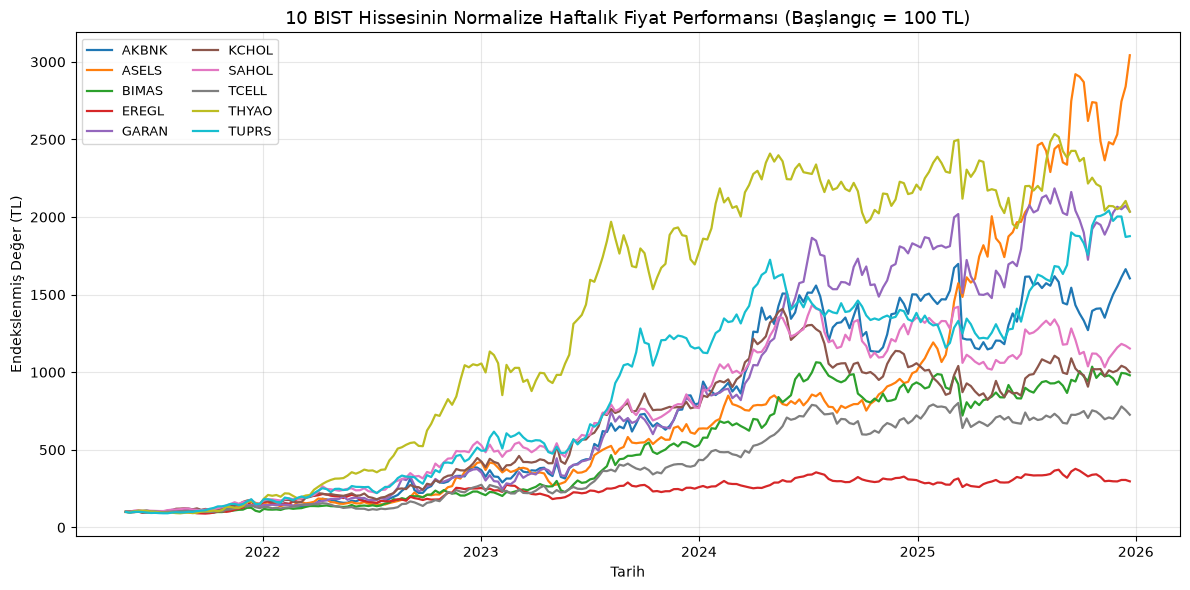

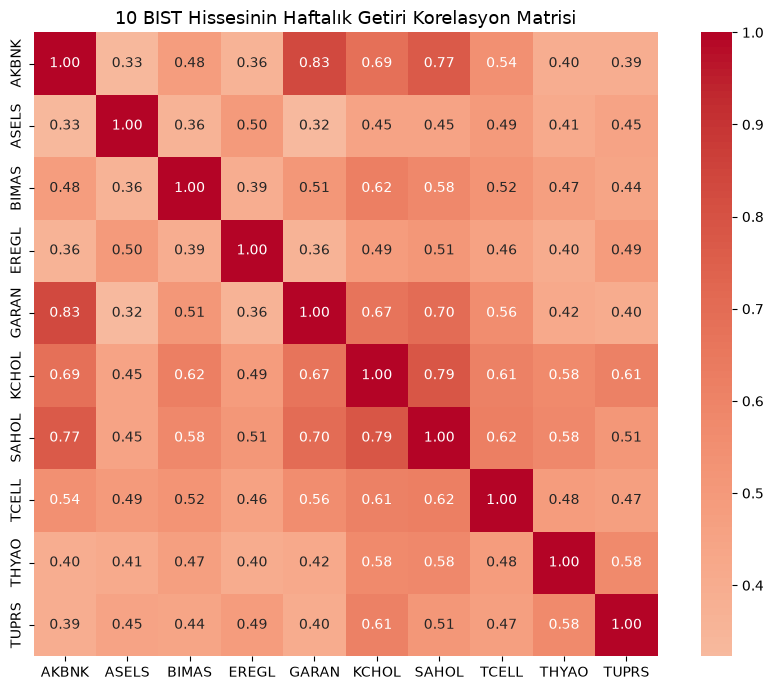

Final CSV kaydedildi: c:\Users\Semih\Desktop\bist-ml-prediction\data\processed\bist10_features.csv
Sözleşme kontrolü BAŞARILI — 16 sütun eksiksiz ve 0 NaN!


In [8]:
# Adım 5: EDA Grafikleri (dpi=300) ve Final Veri Sözleşmesi Kaydı
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Grafik 1: 10 Hissenin 100 TL Başlangıçlı Normalize Haftalık Performansı
pivot_close = df_final.pivot(index="Date", columns="Ticker", values="Close")
normalized = (pivot_close / pivot_close.iloc[0]) * 100

plt.figure(figsize=(12, 6))
for col in normalized.columns:
    plt.plot(normalized.index, normalized[col], label=col.replace(".IS", ""), linewidth=1.6)

plt.title("10 BIST Hissesinin Normalize Haftalık Fiyat Performansı (Başlangıç = 100 TL)", fontsize=13)
plt.xlabel("Tarih")
plt.ylabel("Endekslenmiş Değer (TL)")
plt.legend(ncol=2, fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "normalized_prices.png", dpi=300)
plt.show()

# 2) Grafik 2: Haftalık Getiri Korelasyon Isı Haritası
pivot_ret = df_final.pivot(index="Date", columns="Ticker", values="Return_1W")
pivot_ret.columns = [c.replace(".IS", "") for c in pivot_ret.columns]
corr = pivot_ret.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("10 BIST Hissesinin Haftalık Getiri Korelasyon Matrisi", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=300)
plt.show()

# 3) Final CSV Kaydı ve Sözleşme Doğrulaması
output_path = PROCESSED_DIR / "bist10_features.csv"
df_final.to_csv(output_path, index=False)

expected_cols = [
    "Date", "Ticker", "Close", "Return_1W", "Return_4W", "Return_12W",
    "RSI_14", "MACD", "MACD_Signal", "EMA_Diff", "BB_Width",
    "Volatility_12W", "Volume_Change", "XU100_Rel_Strength",
    "Future_Return_1W", "Target_1W"
]
assert list(df_final.columns) == expected_cols, "Sütun sözleşmesi uyuşmuyor!"
assert df_final.isna().sum().sum() == 0, "Tabloda NaN değer var!"

print("Final CSV kaydedildi:", output_path)
print("Sözleşme kontrolü BAŞARILI — 16 sütun eksiksiz ve 0 NaN!")